# Spotify Songs 2023 – EDA

## 1. Problem Definition and Understanding

**Dataset:** https://www.kaggle.com/datasets/nelgiriyewithana/top-spotify-songs-2023

**Goal:** Find patterns in the most streamed Spotify songs of 2023.

### Key Questions
- Which artist has the most songs in the list?
- What are the most streamed songs?
- Are danceable songs streamed more?
- Are newer songs more common in the list?
- Are there more Major or Minor songs?

## 2. Import Libraries

In [3]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Utilities
import warnings
warnings.filterwarnings("ignore")

# Plot Style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Load the Dataset

In [4]:
df = pd.read_csv("spotify-2023.csv", encoding="latin-1")

## 4. Data Understanding

In [5]:
# Display the first 5 rows of the dataset
df.head()

,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,...,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,2023,7,14,553,147,141381703,43,...,125,B,Major,80,89,83,31,0,8,4
1,LALA,Myke Towers,1,2023,3,23,1474,48,133716286,48,...,92,C#,Major,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,1,2023,6,30,1397,113,140003974,94,...,138,F,Major,51,32,53,17,0,31,6
3,Cruel Summer,Taylor Swift,1,2019,8,23,7858,100,800840817,116,...,170,A,Major,55,58,72,11,0,11,15
4,WHERE SHE GOES,Bad Bunny,1,2023,5,18,3133,50,303236322,84,...,144,A,Minor,65,23,80,14,63,11,6


In [6]:
# Display the last 5 rows of the dataset
df.tail()

,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,...,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
948,My Mind & Me,Selena Gomez,1,2022,11,3,953,0,91473363,61,...,144,A,Major,60,24,39,57,0,8,3
949,Bigger Than The Whole Sky,Taylor Swift,1,2022,10,21,1180,0,121871870,4,...,166,F#,Major,42,7,24,83,1,12,6
950,A Veces (feat. Feid),"Feid, Paulo Londra",2,2022,11,3,573,0,73513683,2,...,92,C#,Major,80,81,67,4,0,8,6
951,En La De Ella,"Feid, Sech, Jhayco",3,2022,10,20,1320,0,133895612,29,...,97,C#,Major,82,67,77,8,0,12,5
952,Alone,Burna Boy,1,2022,11,4,782,2,96007391,27,...,90,E,Minor,61,32,67,15,0,11,5


In [7]:
# Display column names as a list
df.columns.tolist()

['track_name',
 'artist(s)_name',
 'artist_count',
 'released_year',
 'released_month',
 'released_day',
 'in_spotify_playlists',
 'in_spotify_charts',
 'streams',
 'in_apple_playlists',
 'in_apple_charts',
 'in_deezer_playlists',
 'in_deezer_charts',
 'in_shazam_charts',
 'bpm',
 'key',
 'mode',
 'danceability_%',
 'valence_%',
 'energy_%',
 'acousticness_%',
 'instrumentalness_%',
 'liveness_%',
 'speechiness_%']

In [8]:
# Check the shape of the dataset (rows, columns)
df.shape

(953, 24)

In [9]:
# Display basic information: data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   track_name            953 non-null    object
 1   artist(s)_name        953 non-null    object
 2   artist_count          953 non-null    int64 
 3   released_year         953 non-null    int64 
 4   released_month        953 non-null    int64 
 5   released_day          953 non-null    int64 
 6   in_spotify_playlists  953 non-null    int64 
 7   in_spotify_charts     953 non-null    int64 
 8   streams               953 non-null    object
 9   in_apple_playlists    953 non-null    int64 
 10  in_apple_charts       953 non-null    int64 
 11  in_deezer_playlists   953 non-null    object
 12  in_deezer_charts      953 non-null    int64 
 13  in_shazam_charts      903 non-null    object
 14  bpm                   953 non-null    int64 
 15  key                   858 non-null    ob

`streams`, `in_deezer_playlists` and `in_shazam_charts` should be numbers, not text.

In [10]:
# Summary statistics for numerical columns
df.describe()

,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,in_apple_playlists,in_apple_charts,in_deezer_charts,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
count,953.000000,953.000000,953.000000,953.000000,953.000000,953.000000,953.000000,953.000000,953.000000,953.000000,953.00000,953.000000,953.000000,953.000000,953.000000,953.000000,953.000000
mean,1.556139,2018.238195,6.033578,13.930745,5200.124869,12.009444,67.812172,51.908709,2.666317,122.540399,66.96957,51.431270,64.279119,27.057712,1.581322,18.213012,10.131165
std,0.893044,11.116218,3.566435,9.201949,7897.608990,19.575992,86.441493,50.630241,6.035599,28.057802,14.63061,23.480632,16.550526,25.996077,8.409800,13.711223,9.912888
min,1.000000,1930.000000,1.000000,1.000000,31.000000,0.000000,0.000000,0.000000,0.000000,65.000000,23.00000,4.000000,9.000000,0.000000,0.000000,3.000000,2.000000
25%,1.000000,2020.000000,3.000000,6.000000,875.000000,0.000000,13.000000,7.000000,0.000000,100.000000,57.00000,32.000000,53.000000,6.000000,0.000000,10.000000,4.000000
50%,1.000000,2022.000000,6.000000,13.000000,2224.000000,3.000000,34.000000,38.000000,0.000000,121.000000,69.00000,51.000000,66.000000,18.000000,0.000000,12.000000,6.000000
75%,2.000000,2022.000000,9.000000,22.000000,5542.000000,16.000000,88.000000,87.000000,2.000000,140.000000,78.00000,70.000000,77.000000,43.000000,0.000000,24.000000,11.000000
max,8.000000,2023.000000,12.000000,31.000000,52898.000000,147.000000,672.000000,275.000000,58.000000,206.000000,96.00000,97.000000,97.000000,97.000000,91.000000,97.000000,64.000000


## 5. Data Cleaning

In [11]:
# Rename columns to cleaner names
df = df.rename(columns={
    "artist(s)_name": "artist_name",
    "danceability_%": "danceability",
    "valence_%": "valence",
    "energy_%": "energy",
    "acousticness_%": "acousticness",
    "instrumentalness_%": "instrumentalness",
    "liveness_%": "liveness",
    "speechiness_%": "speechiness"
})

df.head()

,track_name,artist_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,...,bpm,key,mode,danceability,valence,energy,acousticness,instrumentalness,liveness,speechiness
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,2023,7,14,553,147,141381703,43,...,125,B,Major,80,89,83,31,0,8,4
1,LALA,Myke Towers,1,2023,3,23,1474,48,133716286,48,...,92,C#,Major,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,1,2023,6,30,1397,113,140003974,94,...,138,F,Major,51,32,53,17,0,31,6
3,Cruel Summer,Taylor Swift,1,2019,8,23,7858,100,800840817,116,...,170,A,Major,55,58,72,11,0,11,15
4,WHERE SHE GOES,Bad Bunny,1,2023,5,18,3133,50,303236322,84,...,144,A,Minor,65,23,80,14,63,11,6


In [12]:
# Convert streams to numbers
# errors="coerce" turns any wrong value into NaN
df["streams"] = pd.to_numeric(df["streams"], errors="coerce")

# Show the rows with a wrong value
df[df["streams"].isna()]

,track_name,artist_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,...,bpm,key,mode,danceability,valence,energy,acousticness,instrumentalness,liveness,speechiness
574,Love Grows (Where My Rosemary Goes),Edison Lighthouse,1,1970,1,1,2877,0,NaN,16,...,110,A,Major,53,75,69,7,0,17,3


In [13]:
# Remove the commas from the numbers, then convert them to numbers
df["in_deezer_playlists"] = pd.to_numeric(df["in_deezer_playlists"].str.replace(",", ""))
df["in_shazam_charts"] = pd.to_numeric(df["in_shazam_charts"].str.replace(",", ""))

In [14]:
# Check for missing values in each column
df.isna().sum()

,0
track_name,0
artist_name,0
artist_count,0
released_year,0
released_month,0
released_day,0
in_spotify_playlists,0
in_spotify_charts,0
streams,1
in_apple_playlists,0


- `streams`: 1 wrong value → drop
- `in_shazam_charts`: missing = not in charts → fill with 0
- `key`: 95 missing (10%) → fill with 'Unknown'

In [15]:
df = df.dropna(subset=["streams"])
df["in_shazam_charts"] = df["in_shazam_charts"].fillna(0)
df["key"] = df["key"].fillna("Unknown")

# Fix the data types after cleaning
df["streams"] = df["streams"].astype("int64")
df["in_shazam_charts"] = df["in_shazam_charts"].astype(int)

df.isna().sum().sum()

np.int64(0)

In [16]:
# Check for duplicated songs (same song name and same artist)
df.duplicated(subset=["track_name", "artist_name"]).sum()

np.int64(4)

In [17]:
# Remove duplicated songs
df = df.drop_duplicates(subset=["track_name", "artist_name"])

df.shape  # confirm the new size

(948, 24)

In [18]:
# Check the data types after cleaning
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 948 entries, 0 to 952
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   track_name            948 non-null    object
 1   artist_name           948 non-null    object
 2   artist_count          948 non-null    int64 
 3   released_year         948 non-null    int64 
 4   released_month        948 non-null    int64 
 5   released_day          948 non-null    int64 
 6   in_spotify_playlists  948 non-null    int64 
 7   in_spotify_charts     948 non-null    int64 
 8   streams               948 non-null    int64 
 9   in_apple_playlists    948 non-null    int64 
 10  in_apple_charts       948 non-null    int64 
 11  in_deezer_playlists   948 non-null    int64 
 12  in_deezer_charts      948 non-null    int64 
 13  in_shazam_charts      948 non-null    int64 
 14  bpm                   948 non-null    int64 
 15  key                   948 non-null    object


## 6. Descriptive Statistics (danceability)

In [19]:
dance = df["danceability"]

# --- Central tendency ---
mean_dance   = dance.mean()
median_dance = dance.median()
mode_dance   = dance.mode()

# --- Spread ---
min_dance   = dance.min()
max_dance   = dance.max()
range_dance = max_dance - min_dance
std_dance   = dance.std()

print(f"Mean danceability   : {mean_dance:.2f}")
print(f"Median danceability : {median_dance:.2f}")
print(f"Mode danceability   : {list(mode_dance.values)}")
print(f"Min, Max            : {min_dance}, {max_dance}")
print(f"Range               : {range_dance}")
print(f"Std deviation       : {std_dance:.2f}")

Mean danceability   : 66.97
Median danceability : 69.00
Mode danceability   : [np.int64(70)]
Min, Max            : 23, 96
Range               : 73
Std deviation       : 14.64


Average danceability is about 67%, so most popular songs are danceable.

## 7. EDA

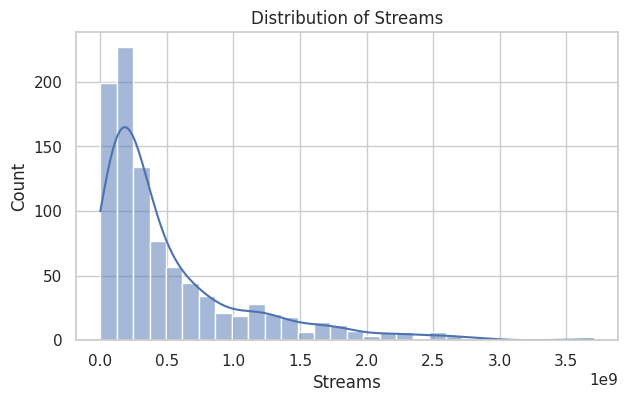

In [20]:
# Distribution of streams
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="streams", bins=30, kde=True)

plt.title("Distribution of Streams")
plt.xlabel("Streams")
plt.ylabel("Count")
plt.show()

Right-skewed: most songs have less than 1 billion streams.

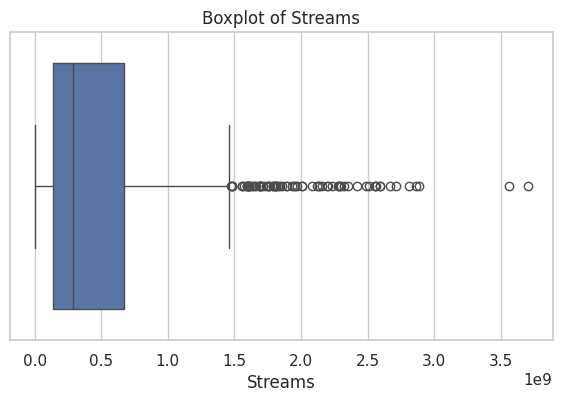

In [21]:
# Boxplot to detect outliers in streams
plt.figure(figsize=(7,4))
sns.boxplot(x=df["streams"])

plt.title("Boxplot of Streams")
plt.xlabel("Streams")
plt.show()

The outliers are real hit songs, so we keep them.

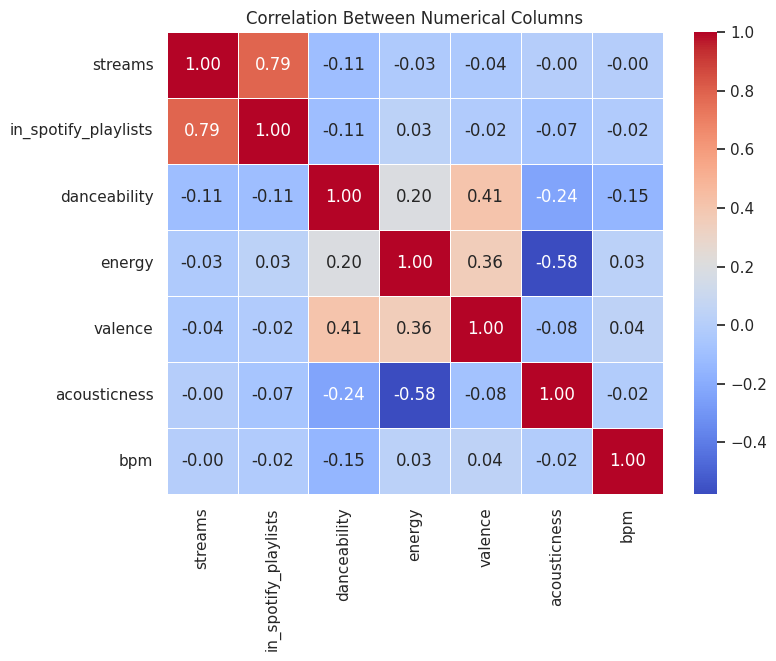

In [22]:
# Correlation heatmap for numerical columns
numeric_cols = ["streams", "in_spotify_playlists", "danceability", "energy", "valence", "acousticness", "bpm"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title("Correlation Between Numerical Columns")
plt.show()

Streams is strongly related to playlists (0.79). Music features have almost no relation with streams.

**Which artist has the most songs in the list?**

artist_name
Taylor Swift      34
The Weeknd        21
SZA               19
Bad Bunny         19
Harry Styles      17
Kendrick Lamar    12
Morgan Wallen     11
Ed Sheeran         9
Feid               8
BTS                8
Name: count, dtype: int64


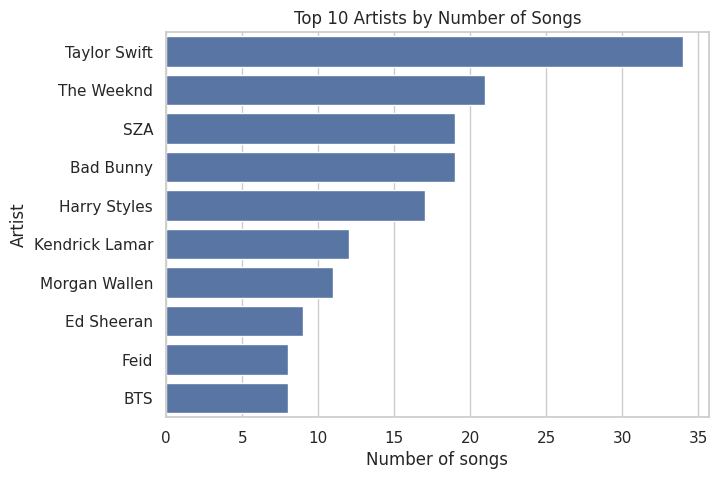

In [23]:
# 1) Numerical summary
top_artists = df["artist_name"].value_counts().head(10)
print(top_artists)

# 2) Visual comparison
plt.figure(figsize=(7, 5))
sns.barplot(x=top_artists.values, y=top_artists.index)
plt.title("Top 10 Artists by Number of Songs")
plt.xlabel("Number of songs")
plt.ylabel("Artist")
plt.show()

**Taylor Swift** (34 songs).

**What are the most streamed songs?**

                                        track_name  \
55                                 Blinding Lights   
179                                   Shape of You   
86                               Someone You Loved   
620                                   Dance Monkey   
41   Sunflower - Spider-Man: Into the Spider-Verse   
162                                      One Dance   
84                       STAY (with Justin Bieber)   
140                                       Believer   
725                                         Closer   
48                                         Starboy   

                      artist_name  released_year     streams  
55                     The Weeknd           2019  3703895074  
179                    Ed Sheeran           2017  3562543890  
86                  Lewis Capaldi           2018  2887241814  
620                   Tones and I           2019  2864791672  
41          Post Malone, Swae Lee           2018  2808096550  
162           Drake, WizKid

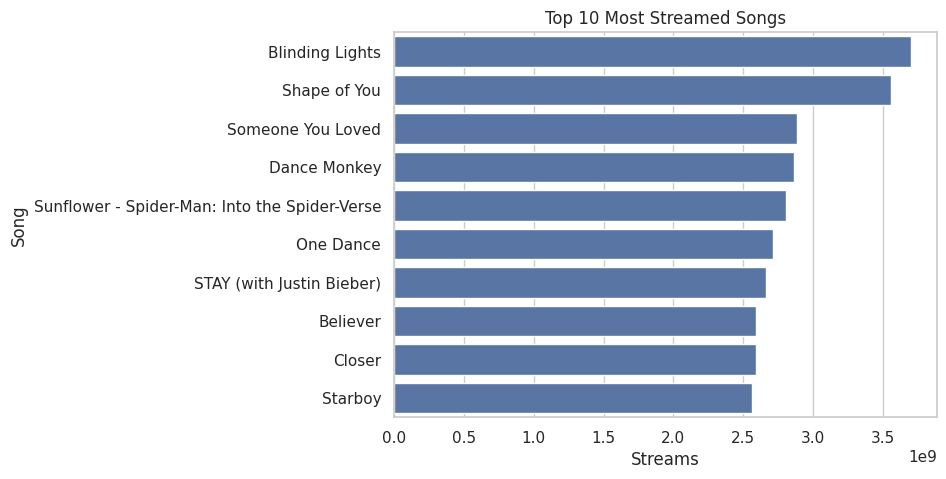

In [24]:
# 1) Numerical summary
top_songs = df.sort_values("streams", ascending=False).head(10)
print(top_songs[["track_name", "artist_name", "released_year", "streams"]])

# 2) Visual comparison
plt.figure(figsize=(7, 5))
sns.barplot(data=top_songs, x="streams", y="track_name")
plt.title("Top 10 Most Streamed Songs")
plt.xlabel("Streams")
plt.ylabel("Song")
plt.show()

**Blinding Lights** by The Weeknd (about 3.7 billion).

**Are danceable songs streamed more?**

              danceability  streams
danceability          1.00    -0.11
streams              -0.11     1.00


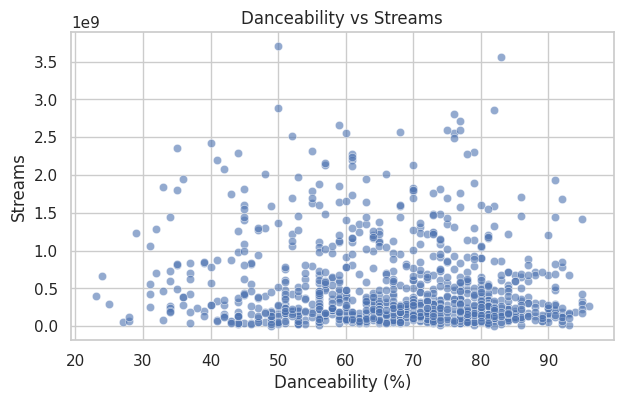

In [25]:
# 1) Numerical summary
print(df[["danceability", "streams"]].corr().round(2))

# 2) Visual comparison
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="danceability", y="streams", alpha=0.6)
plt.title("Danceability vs Streams")
plt.xlabel("Danceability (%)")
plt.ylabel("Streams")
plt.show()

**No** (correlation -0.11).

**Are newer songs more common in the list?**

released_year
2022    399
2023    175
2021    118
2020     37
2019     36
Name: count, dtype: int64
Songs released in 2020 or later: 76.9 %


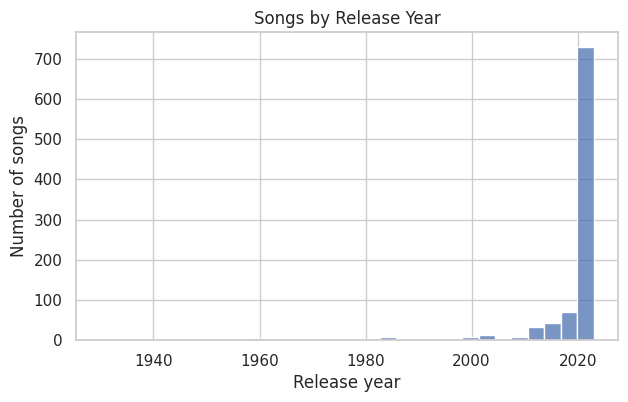

In [26]:
# 1) Numerical summary
print(df["released_year"].value_counts().head())
print("Songs released in 2020 or later:", round((df["released_year"] >= 2020).mean() * 100, 1), "%")

# 2) Visual comparison
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="released_year", bins=30)
plt.title("Songs by Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of songs")
plt.show()

**Yes.** About 77% were released in 2020 or later.

**Are there more Major or Minor songs?**

mode
Major    546
Minor    402
Name: count, dtype: int64
mode
Major    535123196.0
Minor    485352564.0
Name: streams, dtype: float64


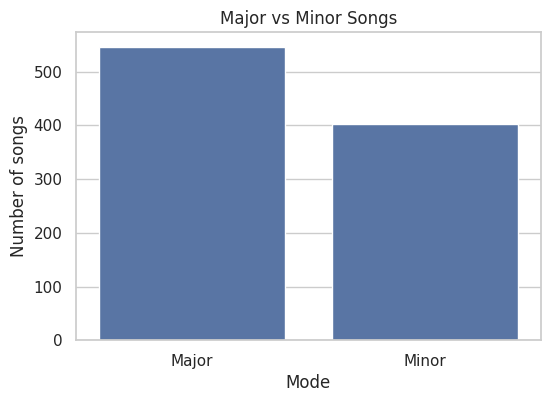

In [27]:
# 1) Numerical summary
print(df["mode"].value_counts())
print(df.groupby("mode")["streams"].mean().round(0))

# 2) Visual comparison
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="mode")
plt.title("Major vs Minor Songs")
plt.xlabel("Mode")
plt.ylabel("Number of songs")
plt.show()

**Major** (546 vs 402).

## 8. Final Insights
- Taylor Swift has the most songs (34).
- Blinding Lights is the most streamed song.
- Danceability does not affect streams.
- 77% of the songs are from 2020 or later.
- Major songs are more common.
- More playlists → more streams.

## 9. Encoding

In [28]:
# Select the features
X = df[["mode", "key", "danceability", "energy", "valence", "acousticness", "bpm", "in_spotify_playlists"]]

# One-Hot Encoding for categorical columns
X_encoded = pd.get_dummies(X, drop_first=True)

X_encoded.head()

,danceability,energy,valence,acousticness,bpm,in_spotify_playlists,mode_Minor,key_A#,key_B,key_C#,key_D,key_D#,key_E,key_F,key_F#,key_G,key_G#,key_Unknown
0,80,83,89,31,125,553,False,False,True,False,False,False,False,False,False,False,False,False
1,71,74,61,7,92,1474,False,False,False,True,False,False,False,False,False,False,False,False
2,51,53,32,17,138,1397,False,False,False,False,False,False,False,True,False,False,False,False
3,55,72,58,11,170,7858,False,False,False,False,False,False,False,False,False,False,False,False
4,65,80,23,14,144,3133,True,False,False,False,False,False,False,False,False,False,False,False


## 10. Save the Data

In [29]:
df.to_csv("clean_data.csv", index=False)
X_encoded.to_csv("spotify_ml_ready.csv", index=False)

print("Files saved!")

Files saved!
